# Scatter Plot

**Family:** Correlation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Correlation:* Show the relationship between two or more variables.

## Design purpose

Each observation is a dot placed by two numeric variables. It is the basic chart for relationships: the direction, strength, shape (linear or curved), clusters and outliers all show at once.

## When to use

- Show whether two numeric variables move together
- Find clusters, gaps and outliers in two-dimensional data
- Explore data before fitting a model

## Avoid when

- There are tens of thousands of points and heavy overplotting (use hexbin or 2-D density)
- One variable is time (use a line chart)
- Readers need exact values (use a table)

## Alternatives

- Hexbin plot
- 2-D density contour
- Bubble chart (adds a third variable)

## Design tips

- Use semi-transparent markers so overlapping points stay visible
- Use at most three colored groups; more is hard to tell apart
- Start axes at sensible values, not necessarily zero

## Example

Height and weight of 300 adults, split by sex (synthetic data).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
pio.templates["vizlib"] = go.layout.Template(layout=dict(
    colorway=PALETTE, font=dict(family="Helvetica, Arial, sans-serif", size=13, color="#0b0b0b"),
    paper_bgcolor="#fcfcfb", plot_bgcolor="#fcfcfb", title=dict(x=0.02, xanchor="left"),
    xaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
    yaxis=dict(gridcolor="#e6e5e1", linecolor="#c9c8c3", zeroline=False),
))
pio.templates.default = "plotly_white+vizlib"

import altair as alt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]


@alt.theme.register("vizlib", enable=True)
def vizlib_theme():
    return alt.theme.ThemeConfig({
        "config": {
            "background": "#fcfcfb",
            "view": {"stroke": None},
            "range": {"category": PALETTE},
            "font": "Helvetica, Arial, sans-serif",
            "title": {"anchor": "start", "fontSize": 14, "color": "#0b0b0b"},
            "axis": {"gridColor": "#e6e5e1", "domainColor": "#c9c8c3", "tickColor": "#c9c8c3",
                     "labelColor": "#52514e", "titleColor": "#52514e", "titleFontWeight": "normal"},
            "legend": {"labelColor": "#52514e", "titleColor": "#52514e"},
        }
    })
pio.renderers.default = "plotly_mimetype+notebook_connected"

### Data

In [2]:
rng = np.random.default_rng(42)
n = 150
height_f = rng.normal(163, 6.5, n)
height_m = rng.normal(177, 7, n)
df = pd.DataFrame({
    "height_cm": np.r_[height_f, height_m],
    "weight_kg": np.r_[0.62 * height_f - 40 + rng.normal(0, 6, n),
                       0.75 * height_m - 55 + rng.normal(0, 7, n)],
    "sex": ["Female"] * n + ["Male"] * n,
})
x, y, hue = "height_cm", "weight_kg", "sex"
labels = dict(x="Height (cm)", y="Weight (kg)", title="Height vs. weight of 300 adults")
df.head()

,height_cm,weight_kg,sex
0,164.980661,72.652111,Female
1,156.240103,47.665696,Female
2,167.877933,69.267286,Female
3,169.113671,62.879324,Female
4,150.318271,52.829382,Female


### Plot

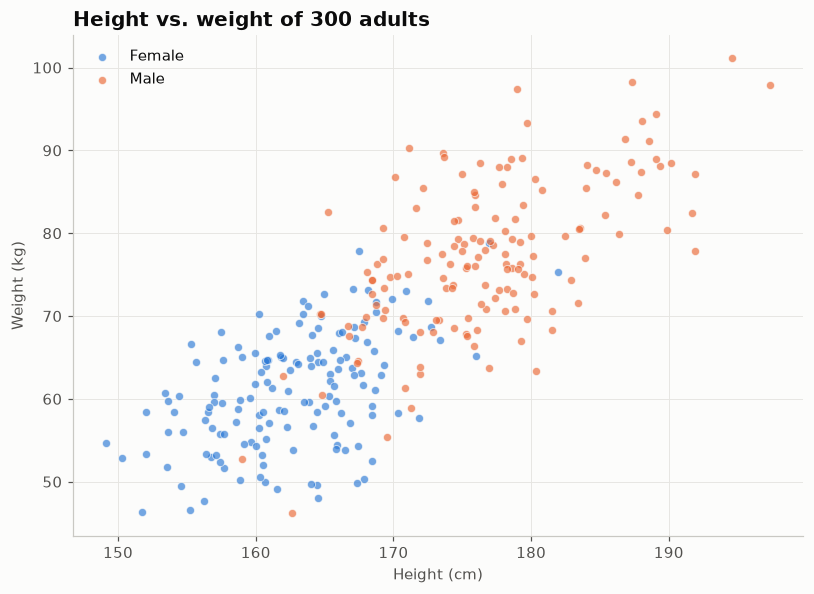

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for color, (name, g) in zip(PALETTE, df.groupby(hue)):
    ax.scatter(g[x], g[y], s=28, alpha=0.65, color=color,
               edgecolor="#fcfcfb", linewidth=0.6, label=name)
ax.set_xlabel(labels["x"])
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.legend(title=None, loc="upper left")
fig.tight_layout()
plt.show()

## How to read it

Each dot is one person. The cloud rises left to right, so taller people tend to weigh more. The two colors overlap heavily, but men cluster further up and to the right.

## The same chart in other libraries

Each version uses the example data above. Pick the library that fits your stack: matplotlib/seaborn for static and print figures, plotly for interactive HTML, Altair for concise declarative specs.

### plotly

In [4]:
import plotly.express as px
fig = px.scatter(df, x=x, y=y, color=hue, opacity=0.7, color_discrete_sequence=PALETTE,
                 labels={x: labels["x"], y: labels["y"]}, title=labels["title"])
fig.update_traces(marker=dict(size=8, line=dict(color="#fcfcfb", width=0.6)))
fig.show()

### altair

In [5]:
import altair as alt
chart = alt.Chart(df).mark_circle(size=40, opacity=0.65).encode(
    x=alt.X(x, title=labels["x"], scale=alt.Scale(zero=False)),
    y=alt.Y(y, title=labels["y"], scale=alt.Scale(zero=False)),
    color=alt.Color(hue, title=None),
    tooltip=[x, y, hue],
).properties(title=labels["title"], width=480, height=340).interactive()
chart

alt.Chart(...)

## Try it with real data

**Source:** plotly.express.data.tips() — restaurant tipping data (Bryant & Smith 1995), bundled with plotly

The dataset ships with an installed package, so this runs offline. It defines the same variables as the example data, so the plot code is unchanged.

In [6]:
import plotly.express as px
df = px.data.tips()                     # 244 restaurant bills (Bryant & Smith, 1995)
x, y, hue = "total_bill", "tip", "sex"
labels = dict(x="Total bill ($)", y="Tip ($)", title="Tip vs. bill size, 244 restaurant bills")
df.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


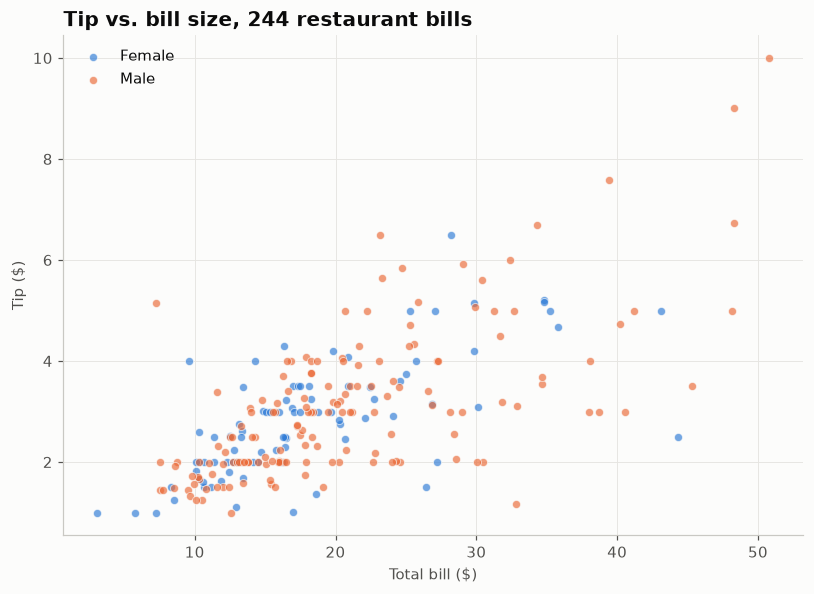

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for color, (name, g) in zip(PALETTE, df.groupby(hue)):
    ax.scatter(g[x], g[y], s=28, alpha=0.65, color=color,
               edgecolor="#fcfcfb", linewidth=0.6, label=name)
ax.set_xlabel(labels["x"])
ax.set_ylabel(labels["y"])
ax.set_title(labels["title"])
ax.legend(title=None, loc="upper left")
fig.tight_layout()
plt.show()

---
Standalone script: [`scatter.py`](scatter.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)